<a href="https://colab.research.google.com/github/chantika-maharani/Project-UAS-Kelompok7/blob/main/01_eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 - Muat Data & Periksa Ukuran Dasar

In [4]:
import pandas as pd

# Memuat dataset dari file CSV yang sudah di-upload ke Colab
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

# Memeriksa ukuran baris dan kolom (untuk Bagian B proposal)
print("Ukuran Dataset (Baris, Kolom):", df.shape)

# Menampilkan 5 baris pertama data
df.head()

Ukuran Dataset (Baris, Kolom): (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


Langkah 2 - Potret Struktur & Tipe Data

In [5]:
# Memeriksa informasi tipe data tiap kolom dan jumlah baris non-null
df.info()

# Ringkasan statistik untuk kolom numerik
print("\nStatistik Kolom Numerik:")
print(df.describe())

# Ringkasan statistik untuk kolom kategori/objek
print("\nStatistik Kolom Kategori:")
print(df.describe(include='object'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

Langkah 3A - Pemeriksaan Nilai Hilang (Missing Values)

In [6]:
# Menghitung jumlah nilai kosong per kolom
missing_values = df.isna().sum()
print("Jumlah nilai kosong per kolom:")
print(missing_values[missing_values > 0])

if missing_values.sum() == 0:
    print("\nHasil: Tidak ada nilai kosong (0) di seluruh kolom dataset.")

Jumlah nilai kosong per kolom:
Series([], dtype: int64)

Hasil: Tidak ada nilai kosong (0) di seluruh kolom dataset.


Langkah 3B - Pemeriksaan Data Hilang Tersamar & Unik Kategori

In [7]:
# Memeriksa nilai unik pada semua kolom berjenis teks/kategori
for col in df.select_dtypes('object').columns:
    print(f"Kolom '{col}':", df[col].unique()[:10])

Kolom 'Gender': ['Female' 'Male']
Kolom 'family_history_with_overweight': ['yes' 'no']
Kolom 'FAVC': ['no' 'yes']
Kolom 'CAEC': ['Sometimes' 'Frequently' 'Always' 'no']
Kolom 'SMOKE': ['no' 'yes']
Kolom 'SCC': ['no' 'yes']
Kolom 'CALC': ['no' 'Sometimes' 'Frequently' 'Always']
Kolom 'MTRANS': ['Public_Transportation' 'Walking' 'Automobile' 'Motorbike' 'Bike']
Kolom 'NObeyesdad': ['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III']


Langkah 3C - Pemeriksaan Baris Duplikat

In [8]:
# Menghitung jumlah baris yang duplikat persis seluruh kolomnya
total_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat identik: {total_duplikat}")

Jumlah baris duplikat identik: 24


Langkah 3D - Pemeriksaan Kolom Konstan & Unik

In [9]:
# Memeriksa apakah ada kolom yang nilainya konstan (sama semua)
n_unique = df.nunique()
print("Jumlah nilai unik per kolom:")
print(n_unique)

kolom_konstan = list(n_unique[n_unique <= 1].index)
print(f"\nKolom konstan (nilai sama semua): {kolom_konstan}")

Jumlah nilai unik per kolom:
Gender                               2
Age                               1402
Height                            1574
Weight                            1525
family_history_with_overweight       2
FAVC                                 2
FCVC                               810
NCP                                635
CAEC                                 4
SMOKE                                2
CH2O                              1268
SCC                                  2
FAF                               1190
TUE                               1129
CALC                                 4
MTRANS                               5
NObeyesdad                           7
dtype: int64

Kolom konstan (nilai sama semua): []


Langkah 3D - Pemeriksaan Kolom Konstan & Unik

In [10]:
# Memeriksa apakah ada kolom yang nilainya konstan (sama semua)
n_unique = df.nunique()
print("Jumlah nilai unik per kolom:")
print(n_unique)

kolom_konstan = list(n_unique[n_unique <= 1].index)
print(f"\nKolom konstan (nilai sama semua): {kolom_konstan}")

Jumlah nilai unik per kolom:
Gender                               2
Age                               1402
Height                            1574
Weight                            1525
family_history_with_overweight       2
FAVC                                 2
FCVC                               810
NCP                                635
CAEC                                 4
SMOKE                                2
CH2O                              1268
SCC                                  2
FAF                               1190
TUE                               1129
CALC                                 4
MTRANS                               5
NObeyesdad                           7
dtype: int64

Kolom konstan (nilai sama semua): []


Langkah 4 & 5 - Fokus Fitur Segmentasi K-Means & Korelasi

In [11]:
# Menampilkan korelasi antar fitur numerik
# (Mengingat dataset ini punya fitur fisik seperti Age, Height, Weight, dll.)
numeric_cols = df.select_dtypes(include=['number']).columns
correlation_matrix = df[numeric_cols].corr()

print("Matriks Korelasi Sederhana:")
print(correlation_matrix)

Matriks Korelasi Sederhana:
             Age    Height    Weight      FCVC       NCP      CH2O       FAF  \
Age     1.000000 -0.025958  0.202560  0.016291 -0.043944 -0.045304 -0.144938   
Height -0.025958  1.000000  0.463136 -0.038121  0.243672  0.213376  0.294709   
Weight  0.202560  0.463136  1.000000  0.216125  0.107469  0.200575 -0.051436   
FCVC    0.016291 -0.038121  0.216125  1.000000  0.042216  0.068461  0.019939   
NCP    -0.043944  0.243672  0.107469  0.042216  1.000000  0.057088  0.129504   
CH2O   -0.045304  0.213376  0.200575  0.068461  0.057088  1.000000  0.167236   
FAF    -0.144938  0.294709 -0.051436  0.019939  0.129504  0.167236  1.000000   
TUE    -0.296931  0.051912 -0.071561 -0.101135  0.036326  0.011965  0.058562   

             TUE  
Age    -0.296931  
Height  0.051912  
Weight -0.071561  
FCVC   -0.101135  
NCP     0.036326  
CH2O    0.011965  
FAF     0.058562  
TUE     1.000000  


Langkah 6 - Visualisasi Data (Contoh Grafik Sebaran & Pencilan)

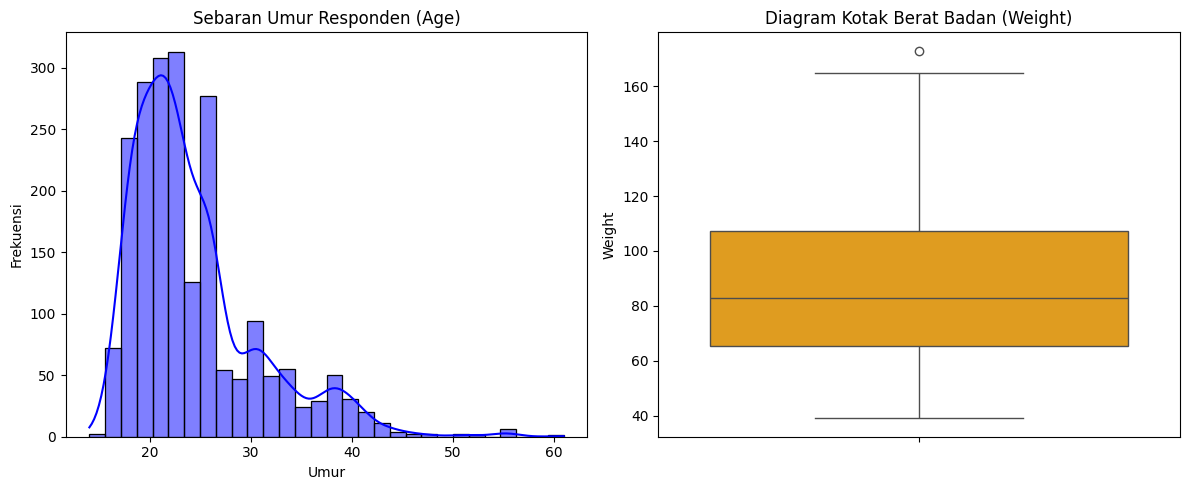

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur ukuran kanvas grafik
plt.figure(figsize=(12, 5))

# Grafik 1: Histogram sebaran umur (Age)
plt.subplot(1, 2, 1)
sns.histplot(df['Age'], bins=30, kde=True, color='blue')
plt.title('Sebaran Umur Responden (Age)')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')

# Grafik 2: Diagram kotak (Boxplot) untuk melihat pencilan pada kolom Weight (Berat Badan)
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Weight'], color='orange')
plt.title('Diagram Kotak Berat Badan (Weight)')
plt.ylabel('Weight')

plt.tight_layout()
plt.show()

Langkah 7 - Pencatatan Keputusan & Penyimpanan Data Bersih

In [13]:

print(f"Ukuran sebelum membersihkan duplikat: {df.shape}")

df_bersih = df.drop_duplicates()

print(f"Ukuran setelah membersihkan duplikat: {df_bersih.shape}")

# Menyimpan hasil ke file CSV bersih untuk digunakan di tahap pemodelan berikutnya
df_bersih.to_csv('data_bersih.csv', index=False)
print("\nFile 'data_bersih.csv' berhasil disimpan!")

Ukuran sebelum membersihkan duplikat: (2111, 17)
Ukuran setelah membersihkan duplikat: (2087, 17)

File 'data_bersih.csv' berhasil disimpan!
